In [ ]:
import os
import re
import pandas as pd

# Check for local file first, then Colab path if running on Google Colab
DATA_FILENAME = 'train-balanced-sarcasm.csv'
if os.path.exists(DATA_FILENAME):
    data_path = DATA_FILENAME
elif os.path.exists(f'/content/drive/MyDrive{DATA_FILENAME}'):
    data_path = f'/content/drive/MyDrive{DATA_FILENAME}'
else:
    data_path = os.path.join('data', DATA_FILENAME)

print(f"Loading dataset from: {data_path}")
df = pd.read_csv(data_path)

# Isolate columns and drop missing values
df = df[['label', 'comment']].dropna(subset=['comment', 'label'])

# Create balanced sample
sarcastic_df = df[df['label'] == 1].sample(n=50000, random_state=42)
normal_df = df[df['label'] == 0].sample(n=50000, random_state=42)
balanced_df = pd.concat([sarcastic_df, normal_df]).sample(frac=1, random_state=42).reset_index(drop=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'\@\w+|\#', '', text)
    text = re.sub(r'r/\w+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

balanced_df['cleaned_comment'] = balanced_df['comment'].apply(clean_text)
balanced_df = balanced_df[balanced_df['cleaned_comment'] != '']
print(f"Final dataset shape: {balanced_df.shape}")

Loading dataset...
Isolating columns and dropping missing values...
Creating balanced sample...
Cleaning text data... (This might take a minute)
Final dataset shape: (99735, 3)
   label                                            comment  \
0      0                          Each seller is different.   
1      0  Amazing what happens when you actually change ...   
2      1  Yes, because refugees have easy access to a sa...   
3      0                            MK Ultra sleeper agent.   
4      0                 I hope that the store was insured.   

                                     cleaned_comment  
0                           each seller is different  
1  amazing what happens when you actually change ...  
2  yes because refugees have easy access to a saf...  
3                             mk ultra sleeper agent  
4                  i hope that the store was insured  


Vectorizing text using TF-IDF...
Building the Neural Network...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training the model...
Epoch 1/5
2494/2494 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.6566 - loss: 0.6193 - val_accuracy: 0.6737 - val_loss: 0.6003
Epoch 2/5
2494/2494 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.7024 - loss: 0.5698 - val_accuracy: 0.6772 - val_loss: 0.6054
Epoch 3/5
2494/2494 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - accuracy: 0.7389 - loss: 0.5256 - val_accuracy: 0.6760 - val_loss: 0.6160
Epoch 4/5
2494/2494 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - accuracy: 0.7810 - loss: 0.4674 - val_accuracy: 0.6757 - val_loss: 0.6497
Epoch 5/5
2494/2494 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.8164 - loss: 0.4037 - val_accuracy: 0.6683 - val_loss: 0.7124
624/624 - 1s - 2ms/step - accuracy: 0.6683 - loss: 0.7124

Final Accuracy: 0.6682709455490112


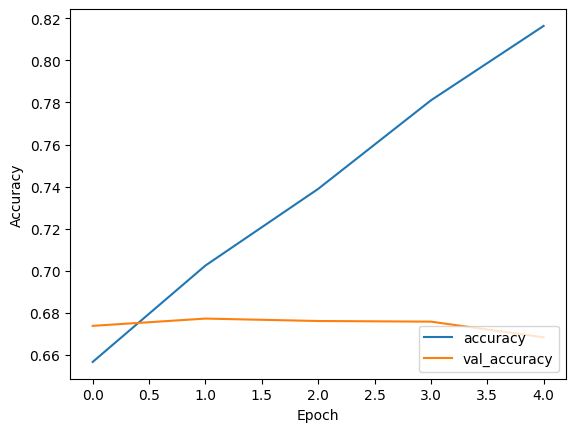

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Vectorize the Text (Turning words into numbers)
print("Vectorizing text using TF-IDF...")
# We limit to 5000 features so it doesn't crash Colab's RAM
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(balanced_df['cleaned_comment']).toarray()
y = balanced_df['label'].values

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Build the Neural Network
print("Building the Neural Network...")
model = models.Sequential()

# First Hidden Layer
# We add input_shape to tell it to expect 5000 words
model.add(layers.Dense(64, activation='relu', input_shape=(5000,)))
model.add(layers.Dropout(0.2))

# Second Hidden Layer
model.add(layers.Dense(16, activation='relu'))

# Output Layer (1 Neuron for Binary Classification, using Sigmoid)
model.add(layers.Dense(1, activation='sigmoid'))

# 4. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 5. Train the Model
# We use fewer epochs (5-10) to prevent overfitting
print("Training the model...")
history = model.fit(X_train, y_train,
                    epochs=5,
                    batch_size=32,
                    validation_data=(X_test, y_test))

# 6. Evaluate and Plot
test_loss, test_acc = model.evaluate(X_test,  y_test, verbose=2)
print("\nFinal Accuracy:", test_acc)

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()

Training the Random Forest Ensemble Model...
(This may take a couple of minutes depending on the Colab instance)
Making predictions...

Random Forest Final Accuracy: 65.18%

Classification Report:
              precision    recall  f1-score   support

      Normal       0.62      0.78      0.69     10023
   Sarcastic       0.70      0.52      0.60      9924

    accuracy                           0.65     19947
   macro avg       0.66      0.65      0.65     19947
weighted avg       0.66      0.65      0.65     19947



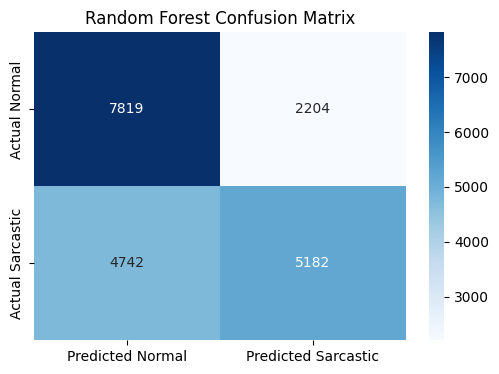


Random Forest Confidence: 64.83%


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Training the Random Forest Ensemble Model...")
print("(This may take a couple of minutes depending on the Colab instance)")

# 1. Initialize the Random Forest
# n_jobs = -1 tells Colab to use all available processors to speed up training
rf_model = RandomForestClassifier(n_estimators=50, max_depth=20, random_state=42, n_jobs=-1)

# 2. Train the Model
rf_model.fit(X_train, y_train)

# 3. Make Predictions on the unseen test data
print("Making predictions...")
rf_predictions = rf_model.predict(X_test)

# 4. Evaluate the Metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)
print(f"\nRandom Forest Final Accuracy: {rf_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, target_names=['Normal', 'Sarcastic']))

# 5. Plot the Confusion Matrix
cm = confusion_matrix(y_test, rf_predictions)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Normal', 'Predicted Sarcastic'],
            yticklabels=['Actual Normal', 'Actual Sarcastic'])
plt.title('Random Forest Confusion Matrix')
plt.show()

import pandas as pd
holdout_sarcastic = df[df['label'] == 1].drop(sarcastic_df.index).sample(n=25000, random_state=100)
holdout_normal = df[df['label'] == 0].drop(normal_df.index).sample(n=25000, random_state=100)
holdout_df = pd.concat([holdout_sarcastic, holdout_normal]).sample(frac=1, random_state=100).reset_index(drop=True)
holdout_df['cleaned_comment'] = holdout_df['comment'].apply(clean_text)
holdout_df = holdout_df[holdout_df['cleaned_comment'] != '']
y_holdout = holdout_df['label'].values
X_holdout_rf = vectorizer.transform(holdout_df['cleaned_comment']).toarray()
rf_holdout_preds = rf_model.predict(X_holdout_rf)
confidence = accuracy_score(y_holdout, rf_holdout_preds)
print(f"\nRandom Forest Confidence: {confidence * 100:.2f}%")

Preparing text for LSTM Neural Network...
Building LSTM Model...
Training LSTM... (If using CPU, this may take a few minutes)
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1247/1247 ━━━━━━━━━━━━━━━━━━━━ 60s 44ms/step - accuracy: 0.6581 - loss: 0.6122 - val_accuracy: 0.6891 - val_loss: 0.5840
Epoch 2/10
1247/1247 ━━━━━━━━━━━━━━━━━━━━ 60s 48ms/step - accuracy: 0.7183 - loss: 0.5530 - val_accuracy: 0.6974 - val_loss: 0.5782
Epoch 3/10
1247/1247 ━━━━━━━━━━━━━━━━━━━━ 76s 44ms/step - accuracy: 0.7383 - loss: 0.5269 - val_accuracy: 0.6897 - val_loss: 0.5966
Epoch 4/10
1247/1247 ━━━━━━━━━━━━━━━━━━━━ 53s 42ms/step - accuracy: 0.7524 - loss: 0.5084 - val_accuracy: 0.6824 - val_loss: 0.6104
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.

Final LSTM Accuracy: 69.74%


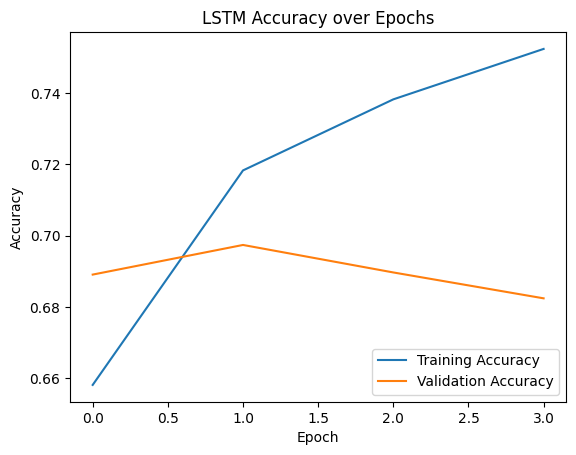


LSTM Confidence: 69.20%


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

print("Preparing text for LSTM Neural Network...")

# 1. Tokenize and Pad the Text (Preserves sequence!)
max_vocab = 10000 # Only learn the 10,000 most common words
max_length = 50   # Cap comments at 50 words to save RAM

tokenizer = Tokenizer(num_words=max_vocab, oov_token="<OOV>")
tokenizer.fit_on_texts(balanced_df['cleaned_comment'])

sequences = tokenizer.texts_to_sequences(balanced_df['cleaned_comment'])
X_seq = pad_sequences(sequences, maxlen=max_length, padding='post', truncating='post')
y_seq = balanced_df['label'].values

# 2. Train/Test Split
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

# 3. Build the Advanced LSTM Architecture
print("Building LSTM Model...")
lstm_model = models.Sequential([
    # Embedding maps words to 16-dimensional semantic space
    layers.Embedding(input_dim=max_vocab, output_dim=16, input_length=max_length),

    # LSTM reads the sequence context
    layers.Bidirectional(layers.LSTM(32, return_sequences=False)),

    # Heavy Dropout to fight overfitting
    layers.Dropout(0.5),

    # Final decision layer
    layers.Dense(1, activation='sigmoid')
])

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 4. The Overfitting Fix: Early Stopping
early_stop = EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True, verbose=1)

# 5. Train the Model
print("Training LSTM... (If using CPU, this may take a few minutes)")
history_lstm = lstm_model.fit(X_train_seq, y_train_seq,
                              epochs=10, # We can set higher epochs because Early Stopping will catch it
                              batch_size=64,
                              validation_data=(X_test_seq, y_test_seq),
                              callbacks=[early_stop])

# 6. Evaluate and Plot
lstm_acc = lstm_model.evaluate(X_test_seq, y_test_seq, verbose=0)[1]
print(f"\nFinal LSTM Accuracy: {lstm_acc * 100:.2f}%")

plt.plot(history_lstm.history['accuracy'], label='Training Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label = 'Validation Accuracy')
plt.title('LSTM Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()

seq_holdout = tokenizer.texts_to_sequences(holdout_df['cleaned_comment'])
X_holdout_lstm = pad_sequences(seq_holdout, maxlen=max_length, padding='post', truncating='post')
confidence = lstm_model.evaluate(X_holdout_lstm, y_holdout, verbose=0)[1]
print(f"\nLSTM Confidence: {confidence * 100:.2f}%")

Vectorizing...
Training AdaBoost Ensemble Model...
Making predictions...

AdaBoost Ensemble Final Accuracy: 56.83%

Classification Report:
              precision    recall  f1-score   support

      Normal       0.54      0.94      0.69     10023
   Sarcastic       0.77      0.19      0.30      9924

    accuracy                           0.57     19947
   macro avg       0.65      0.57      0.50     19947
weighted avg       0.65      0.57      0.50     19947



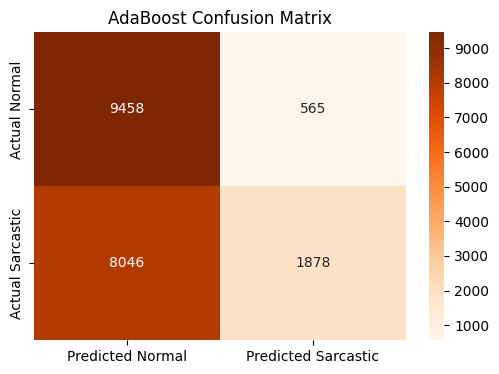

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Vectorizing...")
# Capped at 2500 features for ram
vectorizer_ada = TfidfVectorizer(max_features=2500)
X_ada = vectorizer_ada.fit_transform(balanced_df['cleaned_comment']).toarray()
y_ada = balanced_df['label'].values

X_train_ada, X_test_ada, y_train_ada, y_test_ada = train_test_split(X_ada, y_ada, test_size=0.2, random_state=42)

print("Training AdaBoost Ensemble Model...")
# We used a "Stump" (a tree with a max depth of 1)
base_estimator = DecisionTreeClassifier(max_depth=1)

ada_model = AdaBoostClassifier(estimator=base_estimator, n_estimators=50, random_state=42)

ada_model.fit(X_train_ada, y_train_ada)

print("Making predictions...")
ada_preds = ada_model.predict(X_test_ada)

# Evaluate Metrics
ada_acc = accuracy_score(y_test_ada, ada_preds)
print(f"\nAdaBoost Ensemble Final Accuracy: {ada_acc * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test_ada, ada_preds, target_names=['Normal', 'Sarcastic']))

# Plot Confusion Matrix
cm_ada = confusion_matrix(y_test_ada, ada_preds)
plt.figure(figsize=(6,4))
sns.heatmap(cm_ada, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Predicted Normal', 'Predicted Sarcastic'],
            yticklabels=['Actual Normal', 'Actual Sarcastic'])
plt.title('AdaBoost Confusion Matrix')
plt.show()

In [ ]:
import os
import json
import joblib

# Export models into a local 'models' directory
EXPORT_DIR = 'models'
os.makedirs(EXPORT_DIR, exist_ok=True)

print("Exporting models for deployment...")

# 1. Random Forest & Vectorizer
joblib.dump(rf_model, os.path.join(EXPORT_DIR, 'sarcasm_random_forest.joblib'))
joblib.dump(vectorizer, os.path.join(EXPORT_DIR, 'tfidf_vectorizer.joblib'))
print("Random Forest and TF-IDF Vectorizer exported.")

# 2. LSTM Model (.keras format)
lstm_model.save(os.path.join(EXPORT_DIR, 'sarcasm_lstm.keras'))
print("LSTM Model exported.")

# 3. Keras Tokenizer
tokenizer_json = tokenizer.to_json()
with open(os.path.join(EXPORT_DIR, 'lstm_tokenizer.json'), 'w', encoding='utf-8') as f:
    f.write(json.dumps(tokenizer_json, ensure_ascii=False))
print("Tokenizer JSON exported.")

Exporting models for Flask Deployment...
✅ Random Forest & Vectorizer saved as .joblib
LSTM Model saved as .keras
Tokenizer saved as .json
